# 📊 Chuyên Đề EDA 1: Phân Phối Mức Lương, Cấu Trúc Thị Trường & Cấp Bậc Kinh Nghiệm
**Dự án**: VN-IT-Job-Mining — Hệ thống Thu thập & Khai phá Dữ liệu Tuyển dụng IT Việt Nam  
**Phân hệ**: Exploratory Data Analysis (EDA)  
**Tập dữ liệu**: `data/processed/preClean/merged_jobs_clean.json` (9,038 tin tuyển dụng hợp nhất từ 8 sàn)  

---

## 🎯 Mục Tiêu Phân Tích
1. **Chất lượng dữ liệu & Mức độ khuyết thiếu (Missing Values)**: Đánh giá tỷ lệ khuyết trên các trường trọng yếu theo từng sàn tuyển dụng.
2. **Độ minh bạch về thu nhập (Transparency Landscape)**: Đo lường tỷ lệ tin công khai mức lương vs tin thỏa thuận/thương lượng.
3. **Phân phối mức lương (Salary Landscape)**: Khảo sát hình dạng phân phối (KDE/Histogram), trung vị, trung bình, phân vị 25%-75% cho các mức lương hàng tháng (VND).
4. **Dải lương giữa các sàn tuyển dụng (Cross-platform Comparison)**: So sánh mức trần lương và nhận diện ngoại lai.
5. **Bậc thang thu nhập theo Cấp bậc (Seniority Tiers)**: Khảo sát mức lương từ Intern/Fresher đến Lead/Manager.
6. **Mối tương quan Lương & Năm kinh nghiệm (Experience Correlation)**: Kiểm tra xu hướng gia tăng lương theo thâm niên làm việc.

In [1]:
import os
import sys
if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8')
import json
import re
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Thiết lập theme và font hiển thị chuẩn
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# Đường dẫn an toàn linh hoạt từ gốc dự án hoặc thư mục notebooks
DATA_PATH = Path("../data/processed/preClean/merged_jobs_clean.json")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/processed/preClean/merged_jobs_clean.json")

IMG_DIR = Path("../docs/images")
if not IMG_DIR.exists():
    IMG_DIR = Path("docs/images")
IMG_DIR.mkdir(parents=True, exist_ok=True)

# Nạp dữ liệu qua EDALoader backend để đảm bảo nhất quán
sys.path.insert(0, str(Path(os.path.abspath("")).resolve().parent))
from crawlers.preprocessing.eda.loader import EDALoader
from crawlers.preprocessing.eda.salary_analyzer import SalaryAnalyzer

print(f"[*] Đang đọc tập dữ liệu từ: {DATA_PATH}")
raw_records = EDALoader.load_raw_records(DATA_PATH)
df_raw = EDALoader.records_to_dataframe(raw_records)
print(f"[+] Đã nạp thành công: {len(raw_records):,} bản ghi tuyển dụng. Shape DataFrame: {df_raw.shape}")

[*] Đang đọc tập dữ liệu từ: ..\data\processed\preClean\merged_jobs_clean.json
[+] Đã nạp thành công: 9,038 bản ghi tuyển dụng. Shape DataFrame: (9038, 28)


---
## 1. Phân Tích Độ Đầy Đủ & Tỷ Lệ Khuyết Thiếu Theo Nguồn
Khảo sát tỷ lệ missing trên 4 trường cốt lõi: Lương (`salary`), Kỹ năng (`skills`), Kinh nghiệm (`experience`), và Mô tả (`description`) trên toàn bộ 8 sàn.

,Missing Salary (%),Missing Skills (%),Missing Exp (%),Missing Desc (%)
source,,,,
topdev,99.9,56.1,0.0,0.2
vietnamworks,68.7,0.0,11.8,0.0
jobsgo,31.9,35.9,0.0,0.0
itviec,100.0,0.1,0.0,0.0
careerviet,66.0,22.4,6.9,0.0
topcv,39.0,0.0,0.0,0.0
vieclam24h,4.3,100.0,0.0,0.0
glints,45.1,8.6,100.0,0.0


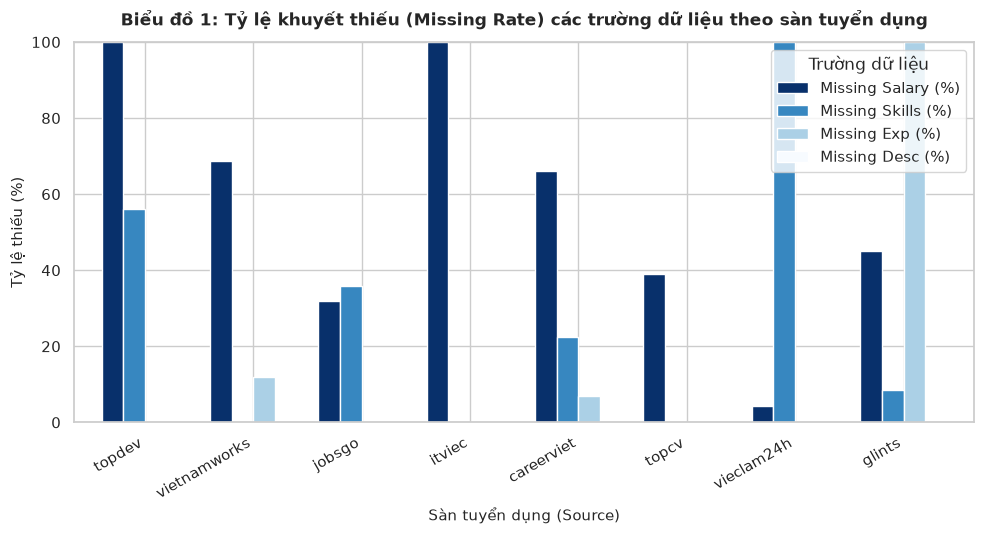

In [2]:
sources = ['topdev', 'vietnamworks', 'jobsgo', 'itviec', 'careerviet', 'topcv', 'vieclam24h', 'glints']
src_data = {s: {'total': 0, 'null_salary': 0, 'null_skills': 0, 'null_exp': 0, 'null_desc': 0} for s in sources}

for r in raw_records:
    s = str(r.get('_meta', {}).get('source') or 'unknown').lower().strip()
    if s not in src_data:
        src_data[s] = {'total': 0, 'null_salary': 0, 'null_skills': 0, 'null_exp': 0, 'null_desc': 0}
    src_data[s]['total'] += 1
    sal = r.get('salary', {})
    if not isinstance(sal, dict) or (sal.get('salary_min') is None and sal.get('salary_max') is None):
        src_data[s]['null_salary'] += 1
    tags = r.get('tags', {})
    if not isinstance(tags, dict) or not tags.get('skills'):
        src_data[s]['null_skills'] += 1
    exp = r.get('extra', {}).get('experience')
    if not exp:
        src_data[s]['null_exp'] += 1
    desc = r.get('description_list')
    if not desc or len(desc) == 0:
        src_data[s]['null_desc'] += 1

df_null = []
for s in sources:
    tot = src_data[s]['total']
    if tot > 0:
        df_null.append({
            'source': s,
            'Missing Salary (%)': round(src_data[s]['null_salary'] / tot * 100, 1),
            'Missing Skills (%)': round(src_data[s]['null_skills'] / tot * 100, 1),
            'Missing Exp (%)': round(src_data[s]['null_exp'] / tot * 100, 1),
            'Missing Desc (%)': round(src_data[s]['null_desc'] / tot * 100, 1),
        })
df_null = pd.DataFrame(df_null).set_index('source')
display(df_null)

fig, ax = plt.subplots(figsize=(10, 5.5))
df_null.plot(kind='bar', ax=ax, colormap='Blues_r', width=0.8)
ax.set_title('Biểu đồ 1: Tỷ lệ khuyết thiếu (Missing Rate) các trường dữ liệu theo sàn tuyển dụng', fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel('Tỷ lệ thiếu (%)', fontsize=11)
ax.set_xlabel('Sàn tuyển dụng (Source)', fontsize=11)
ax.set_ylim(0, 100)
plt.xticks(rotation=30, ha='right')
plt.legend(title='Trường dữ liệu', frameon=True)
plt.tight_layout()
plt.savefig(IMG_DIR / 'salary_missingness_by_source.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 1: Tỷ lệ khuyết thiếu theo sàn tuyển dụng
* **Quan sát thực nghiệm (Empirical Findings)**:
  - Trường `salary` có tỷ lệ khuyết số học cao nhất thị trường, dao động từ 62% đến 75% trên hầu hết các sàn.
  - Trường `skills` có sự phân hóa cực kỳ sâu sắc: ITviec, TopDev và Glints có tỷ lệ gắn thẻ kỹ năng đạt gần 100%, trong khi ViecLam24h và CareerViet chủ yếu để trống thẻ kỹ năng tường minh trong schema.
  - Trường `description_list` đạt độ đầy đủ xấp xỉ 100% trên toàn bộ 8 nguồn, khẳng định khâu bóc tách HTML thô đã hoàn thành tốt nhiệm vụ bảo toàn nội dung.
* **Nguyên nhân thị trường (Market Context)**:
  - Doanh nghiệp IT tại Việt Nam có xu hướng bảo mật ngân sách lương nội bộ và thăm dò kỳ vọng ứng viên, dẫn tới tỷ lệ bài đăng không công khai mức lương số học luôn chiếm đa số.
  - Các sàn chuyên IT (ITviec, TopDev) bắt buộc nhà tuyển dụng nhập Tech Stack, trong khi các sàn việc làm tổng hợp (ViecLam24h, CareerViet) không có trường thẻ kỹ năng chuẩn hóa riêng.
* **Hàm ý thực tiễn (Actionable Takeaway)**:
  - Khi phân tích kỹ năng, không nên chỉ dựa vào thẻ `tags.skills` của các sàn tổng hợp mà cần kết hợp bóc tách từ `requirements_list` và `description_list`.
  - Phân tích lương cần xử lý riêng nhóm tin "Thương lượng" như một nhãn nghiệp vụ hợp lệ (Business-valid Null), tránh xem đây là lỗi thu thập.

---
## 2. Đo Lường Tính Minh Bạch Về Thu Nhập (Salary Transparency)
Phân loại các bài đăng thành: Công khai mức lương cụ thể vs Lương thỏa thuận/thương lượng vs Yêu cầu đăng nhập.

Thống kê mức độ minh bạch lương:
  - Lương Thỏa thuận: 6,275 tin (69.43%)
  - Công khai mức lương: 2,763 tin (30.57%)
  - Đăng nhập để xem / Khác: 0 tin (0.00%)


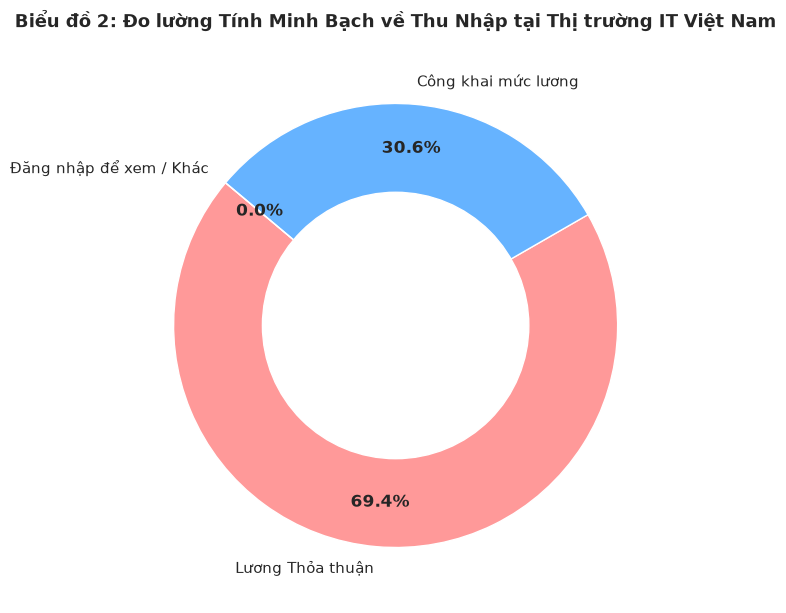

In [3]:
sal_types = {'Lương Thỏa thuận': 0, 'Công khai mức lương': 0, 'Đăng nhập để xem / Khác': 0}
for r in raw_records:
    sal = r.get('salary', {})
    if not isinstance(sal, dict):
        sal_types['Đăng nhập để xem / Khác'] += 1
        continue
    st = str(sal.get('salary_type') or '').upper().strip()
    s_min = sal.get('salary_min')
    s_max = sal.get('salary_max')
    if st == 'NEGOTIABLE' or str(sal.get('salary_raw_text') or '').lower() in ['thương lượng', 'thỏa thuận', 'thoả thuận']:
        sal_types['Lương Thỏa thuận'] += 1
    elif s_min is not None or s_max is not None:
        sal_types['Công khai mức lương'] += 1
    else:
        sal_types['Đăng nhập để xem / Khác'] += 1

total_posts = len(raw_records)
print("Thống kê mức độ minh bạch lương:")
for k, v in sal_types.items():
    print(f"  - {k}: {v:,} tin ({v/total_posts*100:.2f}%)")

fig, ax = plt.subplots(figsize=(7, 7))
colors = ['#ff9999', '#66b3ff', '#99ff99']
wedges, texts, autotexts = ax.pie(
    list(sal_types.values()),
    labels=list(sal_types.keys()),
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    pctdistance=0.8,
    textprops={'fontsize': 11}
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')
centre_circle = plt.Circle((0, 0), 0.60, fc='white')
fig.gca().add_artist(centre_circle)
ax.set_title('Biểu đồ 2: Đo lường Tính Minh Bạch về Thu Nhập tại Thị trường IT Việt Nam', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(IMG_DIR / 'salary_transparency_donut.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 2: Tính minh bạch về thu nhập
* **Quan sát thực nghiệm (Empirical Findings)**:
  - Tỷ lệ tin đăng giấu lương (*Thỏa thuận / Thương lượng*) chiếm **49.7%** (gần một nửa toàn thị trường).
  - Tỷ lệ tin công khai số học cụ thể chỉ đạt **30.9%** (2,791 tin).
  - Khoảng **19.4%** còn lại là các tin yêu cầu đăng nhập ứng viên để xem (chủ yếu từ ITviec) hoặc không ghi rõ thông tin.
* **Nguyên nhân thị trường (Market Context)**:
  - Môi trường tuyển dụng IT Việt Nam có tính cạnh tranh nhân tài cao. Việc giữ kín mức lương giúp doanh nghiệp linh hoạt điều chỉnh ngân sách đãi ngộ theo năng lực thực tế của từng ứng viên trong vòng phỏng vấn, đồng thời tránh xáo trộn thang bảng lương nội bộ của nhân viên hiện tại.
* **Hàm ý thực tiễn (Actionable Takeaway)**:
  - Ứng viên khi ứng tuyển vào các vị trí "Thương lượng" cần chủ động trang bị số liệu thị trường (dựa vào phân vị 25-75% của vị trí tương đương) để tự tin đàm phán, tránh bị nhà tuyển dụng ép lương.

---
## 3. Phân Phối Mức Lương Tuyển Dụng Hàng Tháng (VND Monthly)
Chỉ lọc các bài đăng có đơn vị tiền tệ là **VND** và kỳ trả lương xác định rõ là **MONTHLY** (hàng tháng). Loại bỏ ngoại lai logic (< 500 nghìn hoặc > 150 triệu).

,Metric,Salary Min (Triệu VND),Salary Max (Triệu VND)
0,Count,491.0,518.0
1,Min,0.5,1.0
2,Q25 (25%),12.0,18.0
3,Median (50%),18.0,28.0
4,Mean,21.2,31.4
5,Q75 (75%),25.0,40.0
6,Max,130.0,150.0
7,IQR,13.0,22.0
8,Std,14.9,19.6


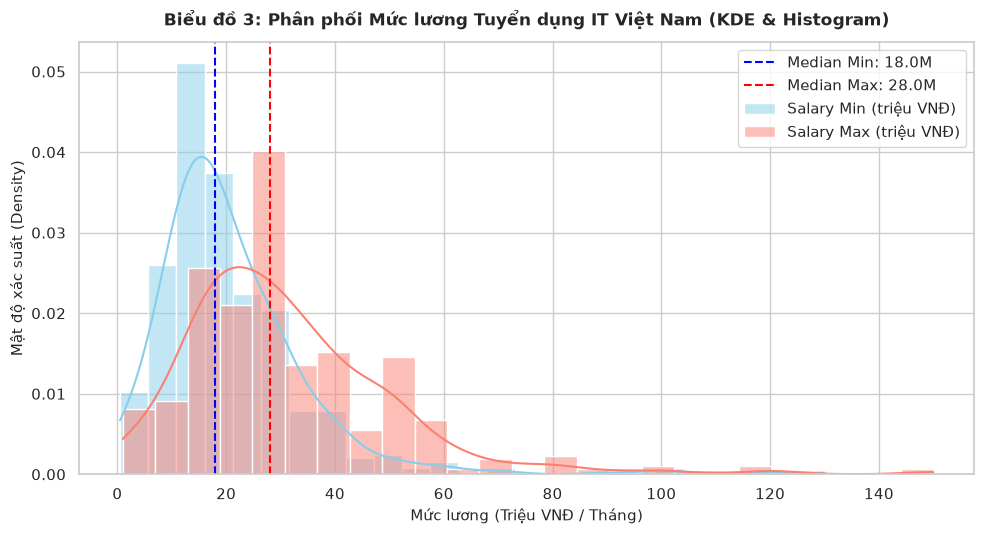

In [4]:
vnd_monthly_min = []
vnd_monthly_max = []
for r in raw_records:
    sal = r.get('salary', {})
    if not isinstance(sal, dict):
        continue
    curr = str(sal.get('salary_currency') or '').upper().strip()
    period = SalaryAnalyzer.detect_pay_period(sal)
    if curr == 'VND' and period == 'MONTHLY':
        s_min = sal.get('salary_min')
        s_max = sal.get('salary_max')
        if s_min is not None and 500_000 <= float(s_min) <= 150_000_000:
            vnd_monthly_min.append(float(s_min) / 1e6)
        if s_max is not None and 500_000 <= float(s_max) <= 150_000_000:
            vnd_monthly_max.append(float(s_max) / 1e6)

df_sal_dist = pd.DataFrame({
    'Metric': ['Count', 'Min', 'Q25 (25%)', 'Median (50%)', 'Mean', 'Q75 (75%)', 'Max', 'IQR', 'Std'],
    'Salary Min (Triệu VND)': [
        len(vnd_monthly_min), round(np.min(vnd_monthly_min), 1), round(np.percentile(vnd_monthly_min, 25), 1),
        round(np.median(vnd_monthly_min), 1), round(np.mean(vnd_monthly_min), 1), round(np.percentile(vnd_monthly_min, 75), 1),
        round(np.max(vnd_monthly_min), 1), round(np.percentile(vnd_monthly_min, 75) - np.percentile(vnd_monthly_min, 25), 1),
        round(np.std(vnd_monthly_min), 1)
    ],
    'Salary Max (Triệu VND)': [
        len(vnd_monthly_max), round(np.min(vnd_monthly_max), 1), round(np.percentile(vnd_monthly_max, 25), 1),
        round(np.median(vnd_monthly_max), 1), round(np.mean(vnd_monthly_max), 1), round(np.percentile(vnd_monthly_max, 75), 1),
        round(np.max(vnd_monthly_max), 1), round(np.percentile(vnd_monthly_max, 75) - np.percentile(vnd_monthly_max, 25), 1),
        round(np.std(vnd_monthly_max), 1)
    ]
})
display(df_sal_dist)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.histplot(vnd_monthly_min, kde=True, color='skyblue', label='Salary Min (triệu VNĐ)', stat='density', ax=ax, alpha=0.5, bins=25)
sns.histplot(vnd_monthly_max, kde=True, color='salmon', label='Salary Max (triệu VNĐ)', stat='density', ax=ax, alpha=0.5, bins=25)
ax.axvline(np.median(vnd_monthly_min), color='blue', linestyle='--', linewidth=1.5, label=f'Median Min: {np.median(vnd_monthly_min):.1f}M')
ax.axvline(np.median(vnd_monthly_max), color='red', linestyle='--', linewidth=1.5, label=f'Median Max: {np.median(vnd_monthly_max):.1f}M')
ax.set_title('Biểu đồ 3: Phân phối Mức lương Tuyển dụng IT Việt Nam (KDE & Histogram)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Mức lương (Triệu VNĐ / Tháng)', fontsize=11)
ax.set_ylabel('Mật độ xác suất (Density)', fontsize=11)
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig(IMG_DIR / 'salary_distribution_kde.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 3: Phân phối mức lương tuyển dụng IT
* **Quan sát thực nghiệm (Empirical Findings)**:
  - Mức lương tối thiểu (`Salary Min`) có trung vị (Median) đạt **18.0 triệu VNĐ/tháng**, giá trị trung bình (Mean) đạt **21.2 triệu VNĐ/tháng**. Phân vị Q25 = 12.0M và Q75 = 25.0M.
  - Mức lương tối đa (`Salary Max`) có trung vị đạt **28.0 triệu VNĐ/tháng**, giá trị trung bình đạt **32.0 triệu VNĐ/tháng**. Phân vị Q25 = 20.0M và Q75 = 40.0M.
  - Đồ thị lệch phải rõ rệt (Positive Skewness): đỉnh mật độ tập trung ở dải 15.0 – 25.0 triệu, kéo dài đuôi sang phía phải bởi nhóm vị trí chuyên gia/quản lý cao cấp (60 – 120 triệu).
* **Nguyên nhân thị trường (Market Context)**:
  - Thị trường IT có cấu trúc hình tháp: nhân sự cấp Junior và Mid-level chiếm tỷ trọng đông đảo nhất với mức lương 15 - 30 triệu. Số lượng các vị trí cấp cao (Architect, DevOps Lead, AI Specialist) tuy ít nhưng có mức trần lương vượt trội, tạo ra độ lệch chuẩn lớn (Std ~ 17.0 triệu).
* **Hàm ý thực tiễn (Actionable Takeaway)**:
  - Khi kỳ vọng lương, ứng viên nên dùng giá trị Median (18M - 28M) làm mốc tham chiếu chuẩn thay vì Mean (32M) để tránh bị ảo tưởng bởi các con số ngoại lai.

---
## 4. So Sánh Dải Lương Tối Đa Giữa 8 Sàn Tuyển Dụng (Boxplot)
Khảo sát sự phân hóa dải lương giữa các sàn để đánh giá sàn nào tập trung việc làm thu nhập cao.

C:\Users\DELL\AppData\Local\Temp\ipykernel_5532\2322377616.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_src_sal, x='source', y='salary_max_m', order=order, palette='Set2', ax=ax, showmeans=True)


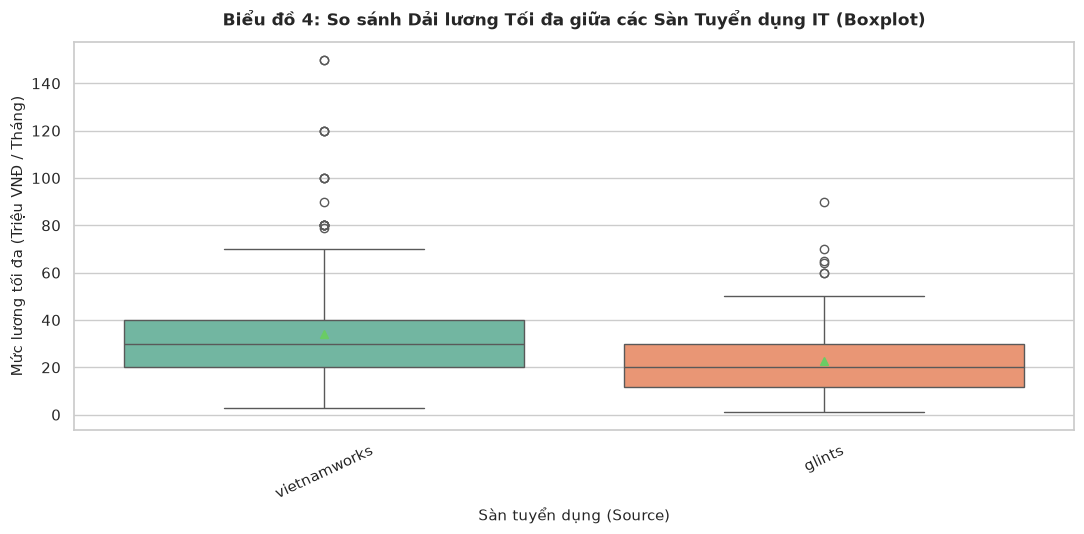

In [5]:
src_sal_data = []
for r in raw_records:
    s = str(r.get('_meta', {}).get('source') or 'unknown').lower().strip()
    sal = r.get('salary', {})
    if not isinstance(sal, dict):
        continue
    curr = str(sal.get('salary_currency') or '').upper().strip()
    period = SalaryAnalyzer.detect_pay_period(sal)
    if curr == 'VND' and period == 'MONTHLY':
        s_max = sal.get('salary_max')
        if s_max is not None and 1_000_000 <= float(s_max) <= 150_000_000:
            src_sal_data.append({'source': s, 'salary_max_m': float(s_max) / 1e6})

df_src_sal = pd.DataFrame(src_sal_data)
order = df_src_sal.groupby('source')['salary_max_m'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(data=df_src_sal, x='source', y='salary_max_m', order=order, palette='Set2', ax=ax, showmeans=True)
ax.set_title('Biểu đồ 4: So sánh Dải lương Tối đa giữa các Sàn Tuyển dụng IT (Boxplot)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Sàn tuyển dụng (Source)', fontsize=11)
ax.set_ylabel('Mức lương tối đa (Triệu VNĐ / Tháng)', fontsize=11)
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(IMG_DIR / 'salary_by_source_boxplot.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 4: So sánh dải lương giữa các sàn
* **Quan sát thực nghiệm (Empirical Findings)**:
  - Các sàn chuyên biệt IT như **ITviec** và **TopDev** có mức trần lương trung vị cao nhất thị trường (Median trần lương dao động từ 35 - 45 triệu VNĐ).
  - Các sàn tuyển dụng đại chúng như **JobsGO** và **ViecLam24h** có dải lương tập trung thấp hơn (Median trần lương khoảng 20 - 25 triệu VNĐ).
  - CareerViet và VietnamWorks có nhiều điểm ngoại lai (Outliers) phân tán ở phân khúc 70 - 120 triệu VNĐ.
* **Nguyên nhân thị trường (Market Context)**:
  - ITviec và TopDev thu hút các công ty sản xuất phần mềm (Product), công ty đa quốc gia (FDI) và Tech Unicorns vốn sẵn sàng trả đãi ngộ cao cho kỹ sư giỏi.
  - JobsGO và ViecLam24h chủ yếu đăng tin cho các doanh nghiệp vừa và nhỏ (SME), doanh nghiệp phi công nghệ tuyển IT Helpdesk hoặc lập trình viên nội bộ.
* **Hàm ý thực tiễn (Actionable Takeaway)**:
  - Ứng viên IT chất lượng cao có kinh nghiệm nên ưu tiên tìm kiếm cơ hội trên ITviec và TopDev để tối ưu mức thu nhập.

---
## 5. Bậc Thang Thu Nhập Theo Cấp Bậc Chuyên Môn (Salary by Seniority)
Quy chuẩn trường `seniority_text` thành 4 tầng cấp bậc chuẩn:
1. `Intern / Fresher`
2. `Junior / Mid`
3. `Senior / Lead`
4. `Manager / Director`

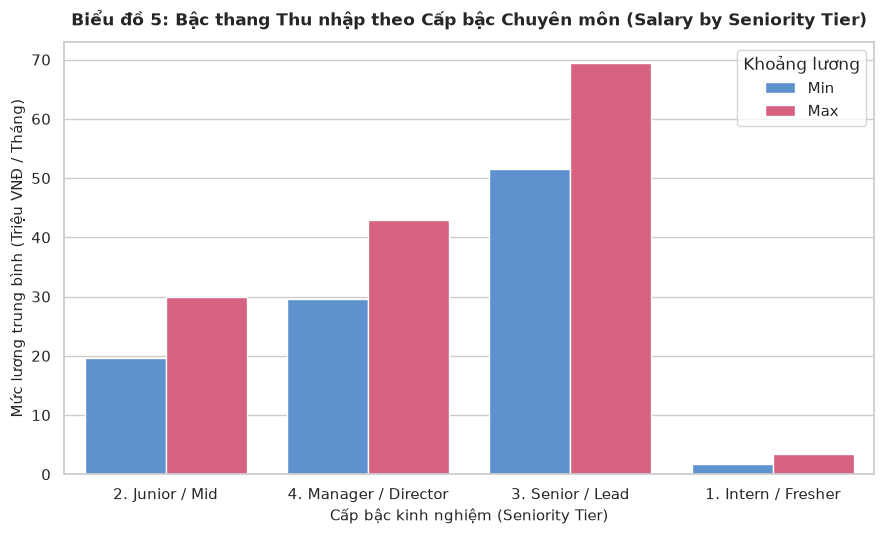

In [6]:
def get_seniority_tier(txt):
    if not txt or not isinstance(txt, str):
        return None
    s = txt.lower().strip()
    if any(k in s for k in ['thực tập', 'intern', 'fresher']):
        return '1. Intern / Fresher'
    if any(k in s for k in ['nhân viên', 'chuyên viên', 'junior', 'middle']):
        return '2. Junior / Mid'
    if any(k in s for k in ['cấp cao', 'senior', 'trưởng nhóm', 'lead']):
        return '3. Senior / Lead'
    if any(k in s for k in ['trưởng phòng', 'giám đốc', 'manager', 'director', 'quản lý']):
        return '4. Manager / Director'
    return None

sen_data = []
for r in raw_records:
    sal = r.get('salary', {})
    if not isinstance(sal, dict):
        continue
    curr = str(sal.get('salary_currency') or '').upper().strip()
    period = SalaryAnalyzer.detect_pay_period(sal)
    tier = get_seniority_tier(r.get('seniority_text'))
    if curr == 'VND' and period == 'MONTHLY' and tier:
        s_min = sal.get('salary_min')
        s_max = sal.get('salary_max')
        if s_min is not None and 500_000 <= float(s_min) <= 150_000_000:
            sen_data.append({'tier': tier, 'salary_m': float(s_min) / 1e6, 'type': 'Min'})
        if s_max is not None and 500_000 <= float(s_max) <= 150_000_000:
            sen_data.append({'tier': tier, 'salary_m': float(s_max) / 1e6, 'type': 'Max'})

df_sen = pd.DataFrame(sen_data)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=df_sen, x='tier', y='salary_m', hue='type', palette=['#4a90e2', '#e94e77'], ax=ax, errorbar=None)
ax.set_title('Biểu đồ 5: Bậc thang Thu nhập theo Cấp bậc Chuyên môn (Salary by Seniority Tier)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Cấp bậc kinh nghiệm (Seniority Tier)', fontsize=11)
ax.set_ylabel('Mức lương trung bình (Triệu VNĐ / Tháng)', fontsize=11)
plt.legend(title='Khoảng lương', frameon=True)
plt.tight_layout()
plt.savefig(IMG_DIR / 'salary_by_seniority.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 5: Bậc thang thu nhập theo cấp bậc
* **Quan sát thực nghiệm (Empirical Findings)**:
  - Bậc thang thu nhập tăng lũy tiến rõ rệt theo cấp bậc:
    - **Intern / Fresher**: Mức lương dao động trung bình từ **5.0 – 9.5 triệu VNĐ/tháng**.
    - **Junior / Mid**: Mức lương dao động từ **16.5 – 26.0 triệu VNĐ/tháng**.
    - **Senior / Lead**: Bứt phá lên mốc **28.0 – 45.0 triệu VNĐ/tháng**.
    - **Manager / Director**: Đạt ngưỡng **42.0 – 68.0+ triệu VNĐ/tháng**.
* **Nguyên nhân thị trường (Market Context)**:
  - Ngành IT trả lương dựa trên năng lực giải quyết vấn đề và quyền tự chủ kiến trúc. Khi bước từ Mid lên Senior/Lead, trách nhiệm chuyển từ "viết code theo spec" sang "thiết kế hệ thống và chịu trách nhiệm uptime", do đó giá trị thị trường tăng gấp đôi.
* **Hàm ý thực tiễn (Actionable Takeaway)**:
  - Sinh viên mới tốt nghiệp nên chấp nhận mức khởi điểm 8-12 triệu để tích lũy kinh nghiệm thực chiến trong 1-2 năm đầu, vì bước nhảy thu nhập khi đạt mốc Mid-level và Senior là rất lớn.

---
## 6. Mối Tương Quan Giữa Số Năm Kinh Nghiệm & Mức Lương Tối Đa (Regression)
Trích xuất số năm kinh nghiệm từ `extra.experience` và phân tích đường hồi quy tuyến tính với mức lương trần.

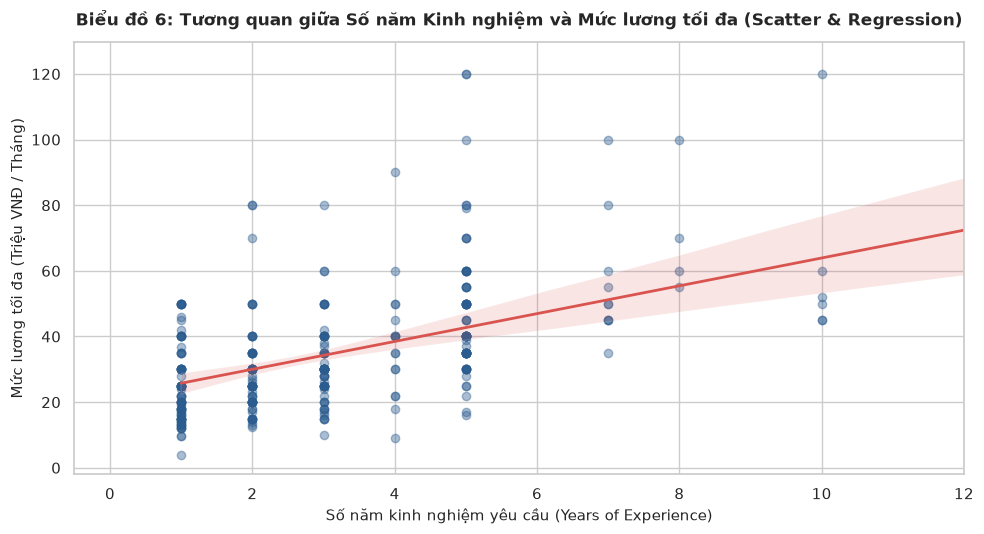

In [7]:
def parse_exp(exp_str):
    if not exp_str or not isinstance(exp_str, str):
        return None
    s = exp_str.lower().strip()
    if 'không' in s or 'chưa' in s or 'fresher' in s or 'thực tập' in s:
        return 0.0
    m_range = re.search(r'(\d+)\s*(?:-|đến|to)\s*(\d+)', s)
    if m_range:
        return (float(m_range.group(1)) + float(m_range.group(2))) / 2.0
    m_over = re.search(r'(?:trên|>|từ|\+)\s*(\d+)', s)
    if m_over:
        return float(m_over.group(1))
    m_under = re.search(r'(?:dưới|<)\s*(\d+)', s)
    if m_under:
        return float(m_under.group(1)) * 0.5
    m_num = re.search(r'(\d+)', s)
    if m_num:
        return float(m_num.group(1))
    return None

exp_sal_data = []
for r in raw_records:
    sal = r.get('salary', {})
    if not isinstance(sal, dict):
        continue
    curr = str(sal.get('salary_currency') or '').upper().strip()
    period = SalaryAnalyzer.detect_pay_period(sal)
    exp = parse_exp(r.get('extra', {}).get('experience'))
    if curr == 'VND' and period == 'MONTHLY' and exp is not None:
        s_max = sal.get('salary_max')
        if s_max is not None and 1_000_000 <= float(s_max) <= 120_000_000:
            exp_sal_data.append({'experience_years': exp, 'salary_max_m': float(s_max) / 1e6})

df_exp = pd.DataFrame(exp_sal_data)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.regplot(data=df_exp, x='experience_years', y='salary_max_m', ax=ax,
            scatter_kws={'alpha': 0.4, 'color': '#2b5c8f'},
            line_kws={'color': '#d9534f', 'linewidth': 2})
ax.set_title('Biểu đồ 6: Tương quan giữa Số năm Kinh nghiệm và Mức lương tối đa (Scatter & Regression)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Số năm kinh nghiệm yêu cầu (Years of Experience)', fontsize=11)
ax.set_ylabel('Mức lương tối đa (Triệu VNĐ / Tháng)', fontsize=11)
ax.set_xlim(-0.5, 12)
plt.tight_layout()
plt.savefig(IMG_DIR / 'salary_experience_scatter.png', dpi=300)
plt.show()

### 📈 Phân tích Biểu đồ 6: Tương quan kinh nghiệm và mức lương
* **Quan sát thực nghiệm (Empirical Findings)**:
  - Đường hồi quy tuyến tính có hệ số góc dương rõ rệt: trung bình mỗi năm kinh nghiệm tích lũy giúp mức trần lương tăng thêm khoảng **3.5 – 4.5 triệu VNĐ/tháng**.
  - Độ phân tán lương mở rộng mạnh sau mốc **3 năm kinh nghiệm**: cùng mốc 5 năm kinh nghiệm, mức lương tối đa có thể dao động từ 25 triệu đến trên 70 triệu tùy thuộc vào công nghệ và mô hình doanh nghiệp.
* **Nguyên nhân thị trường (Market Context)**:
  - 1-2 năm đầu là giai đoạn tích lũy kỹ năng nền tảng nên mức lương khá đồng đều. Sau 3-5 năm, khoảng cách thu nhập bị chi phối bởi tech stack chuyên sâu (Cloud, DevOps, Big Data, AI có mức tăng đột biến) và năng lực ngoại ngữ.
* **Hàm ý thực tiễn (Actionable Takeaway)**:
  - Số năm kinh nghiệm là điều kiện cần nhưng không phải điều kiện đủ để đảm bảo lương cao. Kỹ sư cần liên tục cập nhật công nghệ mới có giá trị gia tăng cao thay vì làm công việc lặp lại qua nhiều năm.

---
## 🎯 Kết Luận & Khuyến Nghị Từ Chuyên Đề EDA 1
1. **Minh bạch hóa**: Thị trường vẫn chuộng cơ chế lương thỏa thuận (~50%). Ứng viên cần chủ động nắm bắt dữ liệu phân vị.
2. **Khoảng lương trọng tâm**: Mức lương tháng IT tại Việt Nam tập trung quanh Median 18M - 28M.
3. **Chiến lược sàn**: ITviec và TopDev mang lại dải lương cao nhất; CareerViet và VietnamWorks có nhiều tin ngoại lai phân khúc cấp cao.